In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import glob
import os
from statsmodels.stats.multitest import fdrcorrection as fdr

In [3]:
# set colour palettes

custom_palette = {
    'SpD1': '#ED5E70',  # blue
    'SpD2': '#CCBB44',  # orange
    'SpD3': '#238934',  # green
    'SpD4': '#66CCEE'   # red
}

marker_dict = {
    'anterior': 'o',   # circle
    'middle': '^',     # triangle
    'posterior': 's'   # square
}

In [4]:
df_control = pd.read_csv('/home/MRMelissaGrantPeters/MinaRyten/Melissa/MRIxST/stats/02c-4layers_qMRIvsST_withendo_with_PrD/Stats_control_qMRI_vs_GO_pathway_LOO_no_SWM_extended_all.csv')
df_control_sig = df_control[df_control['corr_p']<0.05]['GO_type']
df_control_nonsig = df_control[df_control['corr_p']>0.05]['GO_type']
df_control

,GO_type,NRMSE,T,rho,R2,p,corr_p
0,inflammation_GO0001660,118.6,1.024470,0.308196,0.094985,0.329757,0.526565
1,inflammation_GO0001774,137.6,0.232336,0.073274,0.005369,0.820963,0.891160
2,inflammation_GO0001788,132.2,0.464934,0.145461,0.021159,0.651937,0.787560
3,inflammation_GO0002232,79.3,2.918957,0.678271,0.460052,0.015328,0.100354
4,inflammation_GO0002248,97.2,1.663933,0.465654,0.216833,0.127101,0.318027
...,...,...,...,...,...,...,...
2312,myelin_GO0048715,121.1,0.831724,0.254363,0.064701,0.424980,0.610086
2313,myelin_GO0070445,102.7,1.623713,0.456769,0.208638,0.135501,0.332954
2314,myelin_GO0070447,98.3,2.053561,0.544630,0.296622,0.067107,0.218074
2315,myelin_GO0097252,100.9,1.218529,0.359562,0.129285,0.250989,0.461541


In [5]:
df_PD = pd.read_csv('/home/MRMelissaGrantPeters/MinaRyten/Melissa/MRIxST/stats/04c-4layers_PDpredictions_withendo_with_PrD/Projected_PD_pathway_scores_no_SWM.csv')
#df_control_scores = pd.read_csv('../../processed_data/01b-4layers_withendo/05-pathway_scoring/scores_4*.csv', index_col = 0)

FileNotFoundError: [Errno 2] No such file or directory: '../../processed_data/01b-4layers_withendo/05-pathway_scoring/scores_4*.csv'

In [6]:
paths = glob.glob('../../processed_data/01b-4layers_withendo/05-pathway_scoring/scores_4*.csv')


In [7]:
pathways = pd.DataFrame(list(df_PD.drop(columns = ['SpD', 'region']).columns))
pathways = pathways[0].str.split('_PD_predicted', expand = True)[0]
pathways = pathways.str.split('_', expand = True)[1]
pathways

0            None
1       GO0001660
2       GO0001774
3       GO0001788
4       GO0002232
          ...    
2313    GO0048715
2314    GO0070445
2315    GO0070447
2316    GO0097252
2317    GO1904141
Name: 1, Length: 2318, dtype: object

In [113]:
for i in pathways.index:
    #Prepare control data
    path_to_read = [b for b in paths if pathways.iloc[i] in b]
    df_control = pd.read_csv(path_to_read[0], index_col = 0)
    df_control['region'] = df_control['sample_id'].str.split('_', expand = True)[1]
    df_control = df_control.groupby(['bayesSpace_harmony_7', 'region']).median()
    df_control.reset_index(inplace = True)
    df_control.replace({'ant':'anterior', 'mid':'middle', 'post':'posterior'}, inplace = True)
    df_control.rename(columns = {'bayesSpace_harmony_7':'SpD','score':'Control - real scores'}, inplace = True)
    df_control['key'] = df_control['SpD']+df_control['region']
    
    #Prepare PD data
    GO_in_PD = [b for b in list(df_PD.columns) if pathways.iloc[i] in b]
    #variables_to_select = 'SpD'+'region'+GO_in_PD
    subset = df_PD[['SpD','region', GO_in_PD[0]]]
    subset.rename(columns = {GO_in_PD[0] : 'PD - predicted scores'}, inplace = True)
    subset['key'] = subset['SpD']+subset['region']
    
    combined = subset.merge(df_control[['key', 'Control - real scores']], left_on = 'key', right_on = 'key', how = 'inner')
    combined.drop(columns = 'key', inplace = True)
    
    # Subset data
    X = np.asarray(combined["PD - predicted scores"]).reshape(-1, 1)
    Y = np.asarray(combined["Control - real scores"]).reshape(-1, 1)
    
    # Fit model
    model = LinearRegression().fit(X, Y)
    results = []
    results.append(GO_in_PD[0])
    
    # R² score
    r_squared = model.score(X, Y)
    print("R²:", r_squared)
    results.append(r_squared)
    
    # Add intercept
    X_sm = sm.add_constant(X)
    sm_model = sm.OLS(Y, X_sm).fit()
    p_value = sm_model.pvalues[1]  # p-value for the slope
    print("p-value:", p_value)
    results.append(p_value)
    
    r2_text = f"$R^2$ = {r_squared:.3f}"
    pval_text = f"p = {p_value:.3e}"

    if i==0:
        full_results = pd.DataFrame(results).T.set_index(0)
    else:
        full_results = pd.concat([pd.DataFrame(results).T.set_index(0), full_results], axis = 0)
    
full_results.rename(columns = {0: 'pathway', 1: 'R2', 2: 'pval'}, inplace = True)

full_results['padj'] = pd.DataFrame(fdr(full_results['pval'], alpha=0.05, method='indep', is_sorted=False)).T[1]
    #if p_value>0.05:
    #    # Plot
    #    plt.figure(figsize=(6, 4))
    #    plt.plot(X, model.predict(X), color='darkgrey', label='Linear fit')
    #    ax = sns.scatterplot(x=combined["PD - predicted scores"], y=combined["Control - real scores"], hue=combined["SpD"], palette = custom_palette, style=combined["region"], markers=marker_dict)
    #    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    #    plt.title(f"Linear Fit for {GO_in_PD[0]}")
    #    plt.xlabel("PD - predicted scores")
    #    plt.ylabel("Control - real scores")
    #    plt.tight_layout()

    #    plt.text(
    #    x=0.05, y=0.95,               # relative position in axes coordinates
    #    s=f"{r2_text}\n{pval_text}", # multiline annotation
    #    transform=plt.gca().transAxes,
    #    fontsize=10,
    #    verticalalignment='top',
    #    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray"))

    #    plt.show()

In [166]:
full_results.to_csv('../../stats/04c-4layers_PDpredictions_withendo_with_PrD/PD_control_correlation_GOpathways.csv')

In [122]:
full_results['padj'] = list(pd.DataFrame(fdr(full_results['pval'], alpha=0.05, method='indep', is_sorted=False)).T[1])

In [183]:
df_control_sig = df_control[df_control['corr_p']<0.05]['GO_type']
df_control_sig = '|'.join(df_control_sig)

df_control_nonsig = df_control[df_control['corr_p']>0.05]['GO_type']
df_control_nonsig = '|'.join(df_control_nonsig)


In [197]:
nonsig_nonsig = full_results[(full_results['padj']>0.05)]
nonsig_nonsig = nonsig_nonsig[nonsig_nonsig.index.str.contains(df_control_nonsig, case=False, na=False)]
nonsig_nonsig.reset_index(inplace = True)
nonsig_nonsig['category'] = nonsig_nonsig[0].str.split('_', expand = True)[0]
nonsig_nonsig['GO'] = nonsig_nonsig[0].str.split('_', expand = True)[0]+'_'+nonsig_nonsig[0].str.split('_', expand = True)[1]
nonsig_nonsig = nonsig_nonsig.value_counts('category')

In [198]:
nonsig_sig = full_results[(full_results['padj']>0.05)]
nonsig_sig = nonsig_sig[nonsig_sig.index.str.contains(df_control_sig, case=False, na=False)]
nonsig_sig.reset_index(inplace = True)
nonsig_sig['category'] = nonsig_sig[0].str.split('_', expand = True)[0]
nonsig_sig['GO'] = nonsig[0].str.split('_', expand = True)[0]+'_'+nonsig_sig[0].str.split('_', expand = True)[1]
nonsig_sig = nonsig_sig.value_counts('category')

In [199]:
sig_nonsig = full_results[full_results['padj']<0.05]
sig_nonsig = sig_nonsig[sig_nonsig.index.str.contains(df_control_nonsig, case=False, na=False)]
sig_nonsig.reset_index(inplace = True)
sig_nonsig['category'] = sig_nonsig[0].str.split('_', expand = True)[0]
sig_nonsig['GO'] = sig_nonsig[0].str.split('_', expand = True)[0]+'_'+sig_nonsig[0].str.split('_', expand = True)[1]
sig_nonsig = sig_nonsig.value_counts('category')

In [200]:
sig_sig = full_results[full_results['padj']<0.05]
sig_sig = sig_sig[sig_sig.index.str.contains(df_control_sig, case=False, na=False)]
sig_sig.reset_index(inplace = True)
sig_sig['category'] = sig_sig[0].str.split('_', expand = True)[0]
sig_sig['GO'] = sig_sig[0].str.split('_', expand = True)[0]+'_'+sig_sig[0].str.split('_', expand = True)[1]
sig_sig = sig_sig.value_counts('category')

In [201]:
df1 = pd.DataFrame(nonsig_nonsig.rename('nonsig_nonsig')).merge(pd.DataFrame(nonsig_sig.rename('nonsig_sig')), right_index = True, left_index = True, how = 'inner')
df2 = pd.DataFrame(sig_nonsig.rename('sig_nonsig')).merge(pd.DataFrame(sig_sig.rename('sig_sig')), right_index = True, left_index = True, how = 'inner')
df = df1.merge(df2, right_index = True, left_index = True, how = 'inner')
df_percent = df.div(df.sum(axis=1), axis=0) * 100

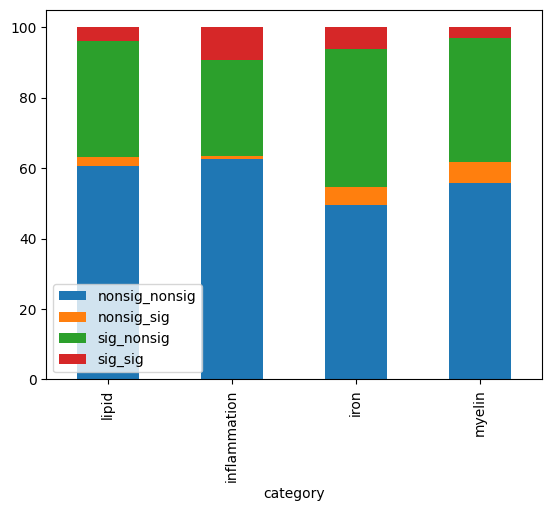

In [202]:
ax = df_percent.plot.bar(stacked=True)

In [205]:
sig_nonsig = full_results[full_results['padj']<0.05]
sig_nonsig = sig_nonsig[sig_nonsig.index.str.contains(df_control_nonsig, case=False, na=False)]

sig_nonsig

,R2,pval,padj
0,,,
myelin_GO0070447_PD_predicted,0.60708,0.002817,0.020252
lipid_GO0045163_PD_predicted,0.644506,0.001669,0.015464
myelin_GO0042552_PD_predicted,0.507663,0.009314,0.034379
myelin_GO0035749_PD_predicted,0.63623,0.001881,0.016426
myelin_GO0033010_PD_predicted,0.494219,0.010765,0.036788
...,...,...,...
inflammation_GO0002523_PD_predicted,0.751248,0.000263,0.006296
inflammation_GO0002438_PD_predicted,0.714695,0.000533,0.009003
inflammation_GO0002269_PD_predicted,0.451953,0.016621,0.046679


In [177]:
nonsig.value_counts('category')

category
lipid           1321
inflammation      61
iron              54
myelin            21
dtype: int64

In [179]:
nonsig[nonsig['R2']<0.4].value_counts('category')

category
lipid           1203
iron              52
inflammation      51
myelin            16
dtype: int64

In [172]:
sig_paths = ['inflammation_GO0006954','myelin_GO0048713','lipid_GO0006631', 'lipid_GO0006682', 'lipid_GO0014808','lipid_GO0030173', 'lipid_GO0033280', 'lipid_GO0034625','lipid_GO0036092', 'lipid_GO0042382', 'lipid_GO0051861','lipid_GO0071007', 'lipid_GO0090556', 'lipid_GO1990531']

pattern = '|'.join(sig_paths)

# Filter rows where any term is found
df_filtered = full_results[full_results.index.str.contains(pattern, case=False, na=False)]
print(df_filtered)




                                           R2      pval      padj
0                                                                
myelin_GO0048713_PD_predicted         0.78343   0.00013  0.004057
lipid_GO1990531_PD_predicted         0.658265  0.001358  0.014306
lipid_GO0090556_PD_predicted         0.720191  0.000482  0.008476
lipid_GO0071007_PD_predicted         0.722675  0.000461  0.008412
lipid_GO0051861_PD_predicted         0.820063   0.00005  0.003071
lipid_GO0042382_PD_predicted           0.9148  0.000001  0.000531
lipid_GO0036092_PD_predicted          0.86738  0.000011  0.001459
lipid_GO0034625_PD_predicted         0.892608  0.000004  0.000854
lipid_GO0033280_PD_predicted         0.922684  0.000001  0.000407
lipid_GO0030173_PD_predicted         0.899862  0.000003  0.000752
lipid_GO0014808_PD_predicted         0.697102  0.000727  0.010202
lipid_GO0006682_PD_predicted          0.91038  0.000001  0.000571
lipid_GO0006631_PD_predicted         0.801781  0.000082  0.003294
inflammati

In [ ]:
custom_palette = {
    'SpD1': '#ED5E70',  # blue
    'SpD2': '#CCBB44',  # orange
    'SpD3': '#238934',  # green
    'SpD4': '#66CCEE'   # red
}

marker_dict = {
    'anterior': 'o',   # circle
    'middle': '^',     # triangle
    'posterior': 's'   # square
}


sns.set_style("whitegrid")

for cell in combined['celltype'].unique():
    res = []
    print(f"Cell type: {cell}")
    
    # Subset data
    df = combined[combined['celltype'] == cell]
    X = np.asarray(df["PD - predicted counts"]).reshape(-1, 1)
    Y = np.asarray(df["Control - real counts"]).reshape(-1, 1)
    
    # Fit model
    model = LinearRegression().fit(X, Y)
    
    # R² score
    r_squared = model.score(X, Y)
    print("R²:", r_squared)
    
    
    # Add intercept
    X_sm = sm.add_constant(X)
    sm_model = sm.OLS(Y, X_sm).fit()
    p_value = sm_model.pvalues[1]  # p-value for the slope
    print("p-value:", p_value)
    
    r2_text = f"$R^2$ = {r_squared:.3f}"
    pval_text = f"p = {p_value:.3e}"

    res.append(cell)
    res.append(r_squared)
    res.append(p_value)
    
    # Plot
    plt.figure(figsize=(5, 4))
    plt.plot(X, model.predict(X), color='darkgrey', label='Linear fit')
    ax = sns.scatterplot(x=df["PD - predicted counts"], y=df["Control - real counts"], hue=df["SpD"], palette = custom_palette, style=df["region"], markers=marker_dict)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.title(f"{cell}")
    plt.xlabel("PD - predicted counts")
    plt.ylabel("Control - real counts")
    plt.tight_layout()
    
    plt.text(
    x=0.05, y=0.95,               # relative position in axes coordinates
    s=f"{r2_text}\n{pval_text}", # multiline annotation
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray"))
    plt.show()
    
    if (cell == 'Astro'):
        full_results = pd.DataFrame(res).T
    else:
        full_results = pd.concat([full_results, pd.DataFrame(res).T])

